Data Points (x_i, y_i):
x = 0.00, y = 0.0000
x = 1.11, y = 2.2303
x = 2.22, y = 6.7054
x = 3.33, y = 10.4759
x = 4.44, y = 15.4672
x = 5.56, y = 27.1692
x = 6.67, y = 46.9388
x = 7.78, y = 68.2490
x = 8.89, y = 83.5511
x = 10.00, y = 94.5598

=== Total Errors (rms) ===
Step-like interpolation error: 7.153811
Linear interpolation error:    0.446261
Cubic spline interpolation error: 0.088205


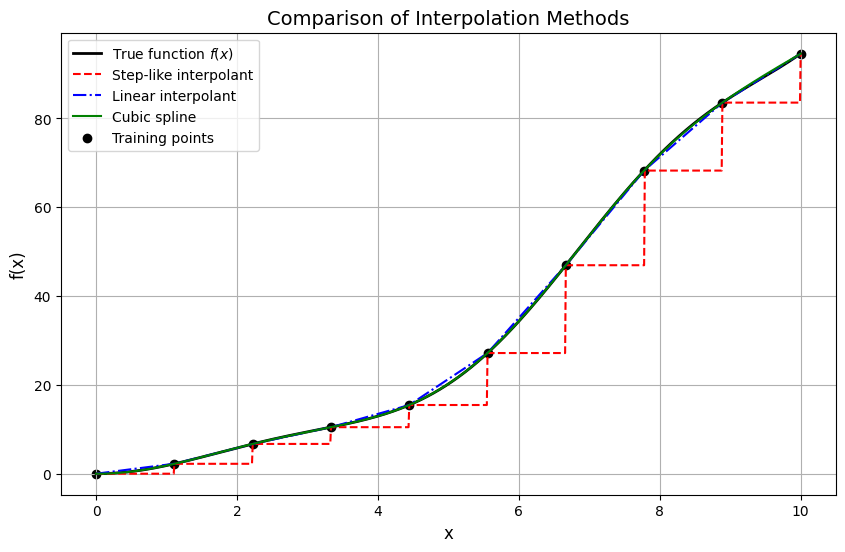

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d, CubicSpline



def f(x):
    return x**2 + x * np.sin(x)
a, b = 0, 10
N = 10
x_train = np.linspace(a, b, N)
y_train = f(x_train)

print("Data Points (x_i, y_i):")
for xi, yi in zip(x_train, y_train):
    print(f"x = {xi:.2f}, y = {yi:.4f}")


# 1. Step-like (piecewise constant) function
f_step = interp1d(x_train, y_train, kind='previous')

# 2. Linear interpolant
f_linear = interp1d(x_train, y_train, kind='linear')

# 3. Cubic spline interpolant
f_cubic = CubicSpline(x_train, y_train)


M = 1000  
x_test = np.linspace(a, b, M)
y_true = f(x_test)
y_step = f_step(x_test)
y_linear = f_linear(x_test)
y_cubic = f_cubic(x_test)


def rms(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))

err_step = rms(y_true, y_step)
err_linear = rms(y_true, y_linear)
err_cubic = rms(y_true, y_cubic)

print("\n=== Total Errors (rms) ===")
print(f"Step-like interpolation error: {err_step:.6f}")
print(f"Linear interpolation error:    {err_linear:.6f}")
print(f"Cubic spline interpolation error: {err_cubic:.6f}")


plt.figure(figsize=(10, 6))
plt.plot(x_test, y_true, 'k-', label='True function $f(x)$', linewidth=2)
plt.plot(x_test, y_step, 'r--', label='Step-like interpolant')
plt.plot(x_test, y_linear, 'b-.', label='Linear interpolant')
plt.plot(x_test, y_cubic, 'g', label='Cubic spline')
plt.scatter(x_train, y_train, color='black', marker='o', label='Training points')
plt.title("Comparison of Interpolation Methods", fontsize=14)
plt.xlabel("x", fontsize=12)
plt.ylabel("f(x)", fontsize=12)
plt.legend()
plt.grid(True)
plt.show()